# 07 학습 — 명령어 10개 + "명령 아님" (11개 클래스)

06 노트북이 만든 목록 `splits_11class.csv`로 다섯 가지를 학습하고 **검증 묶음**에서 비교합니다. 시험 묶음은 최종 평가 때 한 번만 쓰므로 여기서는 불러오지 않습니다.

| 번호 | 실험 | 셀 |
|---|---|---|
| E06 | 0번 기준: 학습 묶음에서 가장 많은 클래스만 고르기 | 4 |
| E07 | 비딥러닝 기준: MFCC 40개의 시간 평균·표준편차 + 로지스틱 회귀 | 4 |
| E08 | 기준선 A: whisper-base 인코더 고정, 30초로 채운 입력, 인코더 출력 앞 50칸(1초) 평균, 마지막 층 + Linear | 5 |
| E09 | 비교: wav2vec2-base 고정, 층별 출력 평균 + Linear (층은 검증으로 고름) | 6 |
| E10 | 팀 모델 B: 로그 멜 스펙트로그램 CNN, 처음부터 학습 | 7 |

지표 (검증 묶음)
- 정확도, 매크로 F1 (11개 클래스). "명령 아님"이 검증의 61%라 정확도는 부풀려지므로 **모델과 에폭은 매크로 F1로 고릅니다**
- 오작동률: 명령이 아닌 소리를 명령으로 판정한 비율. 아는 단어(seen_other)와 잡음(noise)을 따로 계산 (처음 듣는 단어는 시험 묶음에만 있음)
- 놓침률: 명령을 "명령 아님"으로 판정한 비율
- 명령 혼동률: 명령을 다른 명령으로 판정한 비율

Colab: 런타임 유형 T4 GPU → 모두 실행. 목록 파일이 없으면 공개 저장소에서 내려받습니다. Whisper 특징 뽑기가 가장 오래 걸려(05 노트북 기준 1개당 36.5 ms × 44,229개 ≈ 27분) `cache/`에 저장해 두고, `USE_DRIVE = True`면 Google Drive에 저장해 런타임이 끊겨도 남습니다. `SMOKE = True`는 끝까지 도는지만 확인합니다.

In [2]:
# 셀 1. 설정과 버전
import os, sys, time, random, copy, collections, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import transformers
from transformers import WhisperProcessor, WhisperModel
import matplotlib.pyplot as plt

SMOKE = False                  # True: 클래스·무리마다 몇 개만, 1에폭 (결과 숫자는 쓰지 않음)
USE_DRIVE = True              # True: Colab에서 Google Drive를 연결해 특징을 Drive에 저장
RUN_W2V = True                 # E09 wav2vec2 비교를 돌릴지
SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
WHISPER = "openai/whisper-base"
N_KEEP = 50                    # Whisper 인코더 1칸 = 20ms → 앞 50칸 = 1초
LIN_EPOCHS, LIN_LR, LIN_BATCH = 30, 1e-3, 512
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
DTYPE = torch.float16 if AMP else torch.float32
if SMOKE:
    LIN_EPOCHS = B_EPOCHS = 1
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| transformers", transformers.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)
RESULTS = []

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | transformers 5.22.1 | pandas 2.2.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 /content/drive/MyDrive/DL_T02_cache


In [3]:
# 셀 2. 데이터와 목록 (학습·검증만)
os.makedirs(DATA_ROOT, exist_ok=True)
BASE_DIR = os.path.dirname(torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 여기서 쓰지 않음
if SMOKE:
    table = table.groupby(["split", "label", "group"], group_keys=False).sample(frac=1.0, random_state=SEED)
    table = table.groupby(["split", "label", "group"]).head(10).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
data = {s: table[table.split == s].reset_index(drop=True) for s in ["train", "val"]}
Y = {s: torch.tensor(d.label.map(L2I).values) for s, d in data.items()}
GROUP_VAL = data["val"].group.values
print({s: len(d) for s, d in data.items()})
print(data["val"].groupby(["group"]).size().to_dict(), "(검증)")

def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def loader(split, batch):
    return torch.utils.data.DataLoader(Rows(data[split]), batch_size=batch, shuffle=False,
                                       num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

100%|██████████| 2.26G/2.26G [00:17<00:00, 143MB/s]


{'train': 34829, 'val': 9400}
{'command': 3703, 'noise': 117, 'seen_other': 5580} (검증)


In [4]:
# 셀 3. 평가 함수 (11개 클래스 + 기기 조작 지표)
def evaluate(pred, y=None, groups=None):
    y = Y["val"] if y is None else y
    groups = GROUP_VAL if groups is None else groups
    pred, y = pred.cpu(), y.cpu()
    cm = torch.bincount(y * K + pred, minlength=K * K).reshape(K, K).float()
    tp = cm.diag()
    prec, rec = tp / cm.sum(0).clamp(min=1), tp / cm.sum(1).clamp(min=1)
    f1 = 2 * prec * rec / (prec + rec).clamp(min=1e-12)
    p, t = pred.numpy(), y.numpy()
    oth = L2I[OTHER]
    is_cmd = t != oth
    res = {"acc": (tp.sum() / cm.sum()).item(), "f1": f1.mean().item(), "cm": cm,
           "miss": float(np.mean(p[is_cmd] == oth)) if is_cmd.any() else float("nan"),
           "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))) if is_cmd.any() else float("nan")}
    for g in ["seen_other", "noise"]:
        m = groups == g
        res[f"fa_{g}"] = float(np.mean(p[m] != oth)) if m.any() else float("nan")   # 오작동률
    return res

def add_result(eid, setting, r, sec, note=""):
    RESULTS.append({"번호": eid, "설정": setting, "정확도": r["acc"], "매크로 F1": r["f1"],
                    "오작동(아는 단어)": r["fa_seen_other"], "오작동(잡음)": r["fa_noise"],
                    "놓침": r["miss"], "명령 혼동": r["confuse"], "시간(초)": sec, "비고": note})
    print(f"{eid}: 정확도 {r['acc']:.2%} | 매크로 F1 {r['f1']:.4f} | 오작동 아는 단어 {r['fa_seen_other']:.2%}, 잡음 {r['fa_noise']:.2%} | "
          f"놓침 {r['miss']:.2%} | 명령 혼동 {r['confuse']:.2%}")

def fit_linear(Xtr, Ytr, Xva, epochs=LIN_EPOCHS, lr=LIN_LR, batch=LIN_BATCH):
    """표준화한 특징 위에 Linear 하나 학습, 검증 매크로 F1이 가장 높은 에폭의 예측을 돌려줌"""
    torch.manual_seed(SEED)
    Xtr, Xva, Ytr = Xtr.float().to(device), Xva.float().to(device), Ytr.to(device)
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    Xtr, Xva = (Xtr - mu) / sd, (Xva - mu) / sd
    head = nn.Linear(Xtr.shape[1], K).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    best, t0 = None, time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            loss = nn.functional.cross_entropy(head(Xtr[idx]), Ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            pred = head(Xva).argmax(1)
        r = evaluate(pred)
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1, "pred": pred.cpu()}
    best["sec"] = time.time() - t0
    best["params"] = sum(p.numel() for p in head.parameters())
    return best

In [5]:
# 셀 4. 소리 한 번 읽기 → 로그 멜(팀 모델 B용) + MFCC 통계(비딥러닝 기준용), 그리고 E06·E07
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)
mfcc = torchaudio.transforms.MFCC(sample_rate=SR, n_mfcc=40, melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 64}).to(device)

def spec(split):
    def run():
        M, F, t0 = [], [], time.time()
        with torch.no_grad():
            for x in loader(split, 256):
                x = torch.from_numpy(x).to(device)
                M.append(to_db(mel(x)).half().cpu())
                c = mfcc(x)
                F.append(torch.cat([c.mean(-1), c.std(-1)], 1).cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "mfcc": torch.cat(F), "sec": time.time() - t0}
        print(f"  {split}: 로그 멜 {tuple(d['mel'].shape)}, MFCC 통계 {tuple(d['mfcc'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(f"spec11_{split}", run)

sp = {s: spec(s) for s in ["train", "val"]}

# E06 0번 기준
maj = data["train"].label.value_counts().idxmax()
add_result("E06", f"0번 기준: 가장 많은 클래스({maj})만 고름", evaluate(torch.full_like(Y["val"], L2I[maj])), 0.0, "학습 없음")
# E07 비딥러닝 기준
r = fit_linear(sp["train"]["mfcc"], Y["train"], sp["val"]["mfcc"], epochs=1 if SMOKE else 200, lr=1e-2, batch=4096)
add_result("E07", "비딥러닝: MFCC 40개 평균·표준편차 + 로지스틱 회귀", r, r["sec"], f"파라미터 {r['params']:,}")

  train: 로그 멜 (34829, 1, 64, 101), MFCC 통계 (34829, 80) (21초)
  val: 로그 멜 (9400, 1, 64, 101), MFCC 통계 (9400, 80) (10초)
E06: 정확도 60.61% | 매크로 F1 0.0686 | 오작동 아는 단어 0.00%, 잡음 0.00% | 놓침 100.00% | 명령 혼동 0.00%
E07: 정확도 34.12% | 매크로 F1 0.3582 | 오작동 아는 단어 80.65%, 잡음 20.51% | 놓침 7.13% | 명령 혼동 37.94%


In [6]:
# 셀 5. E08 기준선 A — whisper-base 인코더 고정, 30초 입력, 앞 50칸 평균, 마지막 층 + Linear
fe = WhisperProcessor.from_pretrained(WHISPER).feature_extractor
whisper = WhisperModel.from_pretrained(WHISPER, torch_dtype=DTYPE).to(device).eval()
N_WHISPER_ENC = sum(p.numel() for p in whisper.encoder.parameters())

def whisper_feats(split):
    def run():
        X, t0 = [], time.time()
        with torch.no_grad():
            for i, x in enumerate(loader(split, 32)):
                f = fe(list(x), sampling_rate=SR, return_tensors="pt").input_features.to(device, DTYPE)
                hs = whisper.encoder(f, output_hidden_states=True).hidden_states[1:]
                X.append(torch.stack([h[:, :N_KEEP].mean(1) for h in hs], 1).half().cpu())    # (B, 6, 512)
                if i % 200 == 0:
                    print(f"    {split} {i * 32:>6,}/{len(data[split]):,} {time.time() - t0:.0f}초")
        if AMP:
            torch.cuda.synchronize()
        d = {"X": torch.cat(X), "sec": time.time() - t0}
        print(f"  {split}: {tuple(d['X'].shape)} ({d['sec']:.0f}초, 1개당 {d['sec'] / len(data[split]) * 1000:.1f} ms)")
        return d
    return cached(f"whisper_base11_{split}", run)

wf = {s: whisper_feats(s) for s in ["train", "val"]}
WH_SEC = sum(d["sec"] for d in wf.values())
del whisper
if AMP:
    torch.cuda.empty_cache()
A = fit_linear(wf["train"]["X"][:, -1], Y["train"], wf["val"]["X"][:, -1])
add_result("E08", "기준선 A: whisper-base 인코더 고정(30초 입력, 앞 1초 평균) 마지막 층 + Linear", A, WH_SEC + A["sec"],
           f"Linear {A['params']:,}개 학습 / 인코더 {N_WHISPER_ENC:,}개 고정, 특징 {WH_SEC:.0f}초")
layer_f1 = [fit_linear(wf["train"]["X"][:, L], Y["train"], wf["val"]["X"][:, L])["f1"] for L in range(wf["train"]["X"].shape[1])]
print("  참고: 층별 검증 매크로 F1", " ".join(f"{L + 1}층 {f:.3f}" for L, f in enumerate(layer_f1)))

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

    train      0/34,829 3초
    train  6,400/34,829 246초
    train 12,800/34,829 494초
    train 19,200/34,829 741초
    train 25,600/34,829 989초
    train 32,000/34,829 1239초
  train: (34829, 6, 512) (1365초, 1개당 39.2 ms)
    val      0/9,400 2초
    val  6,400/9,400 257초
  val: (9400, 6, 512) (375초, 1개당 39.9 ms)
E08: 정확도 97.82% | 매크로 F1 0.9669 | 오작동 아는 단어 2.22%, 잡음 0.00% | 놓침 0.62% | 명령 혼동 1.57%
  참고: 층별 검증 매크로 F1 1층 0.823 2층 0.880 3층 0.915 4층 0.952 5층 0.965 6층 0.967


In [7]:
# 셀 6. E09 비교 — wav2vec2-base 고정, 층별 평균 + Linear (층은 검증 매크로 F1로 고름)
if RUN_W2V:
    w2v = torchaudio.pipelines.WAV2VEC2_BASE.get_model().to(device).eval()
    def w2v_feats(split):
        def run():
            X, t0 = [], time.time()
            with torch.inference_mode(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                for x in loader(split, 64):
                    layers, _ = w2v.extract_features(torch.from_numpy(x).to(device))
                    X.append(torch.stack([h.mean(1) for h in layers], 1).half().cpu())        # (B, 12, 768)
            if AMP:
                torch.cuda.synchronize()
            d = {"X": torch.cat(X), "sec": time.time() - t0}
            print(f"  {split}: {tuple(d['X'].shape)} ({d['sec']:.0f}초)")
            return d
        return cached(f"w2v_base11_{split}", run)
    vf = {s: w2v_feats(s) for s in ["train", "val"]}
    W2V_SEC = sum(d["sec"] for d in vf.values())
    del w2v
    res = [fit_linear(vf["train"]["X"][:, L], Y["train"], vf["val"]["X"][:, L]) for L in range(12)]
    print("  층별 검증 매크로 F1", " ".join(f"{L + 1}층 {r['f1']:.3f}" for L, r in enumerate(res)))
    bL = int(np.argmax([r["f1"] for r in res]))
    add_result("E09", f"비교: wav2vec2-base 고정 {bL + 1}층(검증 최고) + Linear", res[bL], W2V_SEC + res[bL]["sec"],
               f"특징 {W2V_SEC:.0f}초")

Downloading: "https://download.pytorch.org/torchaudio/models/wav2vec2_fairseq_base_ls960.pth" to /root/.cache/torch/hub/checkpoints/wav2vec2_fairseq_base_ls960.pth


100%|██████████| 360M/360M [00:01<00:00, 276MB/s]


  train: (34829, 12, 768) (64초)
  val: (9400, 12, 768) (17초)
  층별 검증 매크로 F1 1층 0.759 2층 0.804 3층 0.835 4층 0.865 5층 0.905 6층 0.917 7층 0.918 8층 0.911 9층 0.903 10층 0.869 11층 0.803 12층 0.773
E09: 정확도 93.95% | 매크로 F1 0.9183 | 오작동 아는 단어 7.29%, 잡음 3.42% | 놓침 1.65% | 명령 혼동 2.62%


  epoch  1 train loss 1.5251 | val acc 0.3313 | val macro F1 0.4386 | 오작동(단어) 0.824 놓침 0.023 | 4.3초
  epoch  2 train loss 0.7225 | val acc 0.6036 | val macro F1 0.5416 | 오작동(단어) 0.396 놓침 0.140 | 3.7초
  epoch  3 train loss 0.5003 | val acc 0.7237 | val macro F1 0.6991 | 오작동(단어) 0.355 놓침 0.042 | 3.7초
  epoch  4 train loss 0.3927 | val acc 0.5464 | val macro F1 0.6516 | 오작동(단어) 0.673 놓침 0.011 | 3.7초
  epoch  5 train loss 0.3352 | val acc 0.5096 | val macro F1 0.6605 | 오작동(단어) 0.720 놓침 0.011 | 3.8초
  epoch  6 train loss 0.2888 | val acc 0.5281 | val macro F1 0.6402 | 오작동(단어) 0.695 놓침 0.002 | 3.8초
  epoch  7 train loss 0.2578 | val acc 0.6909 | val macro F1 0.7098 | 오작동(단어) 0.401 놓침 0.026 | 3.9초
  epoch  8 train loss 0.2473 | val acc 0.5097 | val macro F1 0.5926 | 오작동(단어) 0.770 놓침 0.001 | 3.9초
  epoch  9 train loss 0.2092 | val acc 0.8883 | val macro F1 0.8382 | 오작동(단어) 0.080 놓침 0.095 | 4.0초
  epoch 10 train loss 0.1892 | val acc 0.6003 | val macro F1 0.6671 | 오작동(단어) 0.493 놓침 0.044 | 4.0초


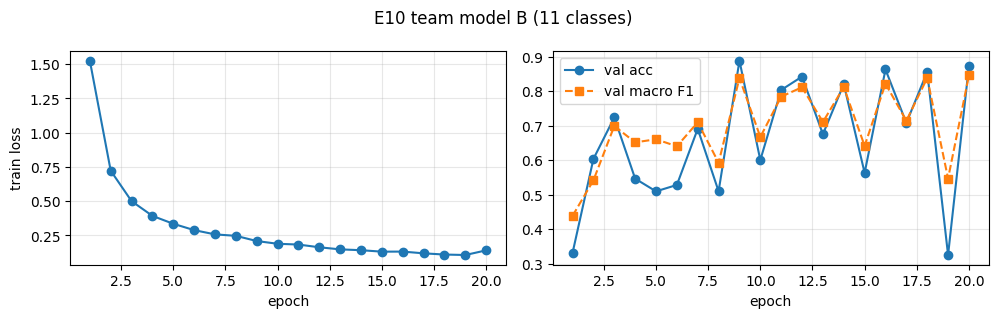

In [8]:
# 셀 7. E10 팀 모델 B — 로그 멜 CNN, 처음부터 학습 (검증 매크로 F1 최고 에폭)
class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

MU, SD = sp["train"]["mel"].float().mean().item(), sp["train"]["mel"].float().std().item()
Xtr = ((sp["train"]["mel"].float() - MU) / SD).to(device); Ytr = Y["train"].to(device)
Xva = ((sp["val"]["mel"].float() - MU) / SD).to(device)
torch.manual_seed(SEED)
cnn = KWSCNN().to(device)
opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
scaler = torch.amp.GradScaler(enabled=AMP)
best, hist, t_start = None, [], time.time()
for ep in range(B_EPOCHS):
    cnn.train(); t0 = time.time(); tot = 0.0
    perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), B_BATCH):
        idx = perm[i:i + B_BATCH]
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            loss = nn.functional.cross_entropy(cnn(Xtr[idx]), Ytr[idx])
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * len(idx)
    cnn.eval()
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
        pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
    r = evaluate(pred)
    hist.append((tot / len(Xtr), r["acc"], r["f1"], time.time() - t0))
    if best is None or r["f1"] > best["f1"]:
        best = {**r, "epoch": ep + 1, "pred": pred.cpu(), "state": copy.deepcopy(cnn.state_dict())}
    print(f"  epoch {ep + 1:2d} train loss {tot / len(Xtr):.4f} | val acc {r['acc']:.4f} | val macro F1 {r['f1']:.4f} | "
          f"오작동(단어) {r['fa_seen_other']:.3f} 놓침 {r['miss']:.3f} | {time.time() - t0:.1f}초")
B = best
B["sec"] = time.time() - t_start
n_cnn = sum(p.numel() for p in cnn.parameters())
add_result("E10", f"팀 모델 B: 로그 멜 CNN {B_CHANNELS}, 처음부터 학습", B, B["sec"], f"파라미터 {n_cnn:,}, 최고 에폭 {B['epoch']}/{B_EPOCHS}")
os.makedirs(CACHE_DIR, exist_ok=True)
torch.save({"state": B["state"], "mu": MU, "sd": SD, "labels": LABELS}, os.path.join(CACHE_DIR, f"E10_cnn11{'_smoke' if SMOKE else ''}.pt"))
h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(range(1, len(h) + 1), h[:, 0], "o-"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss"); ax[0].grid(alpha=.3)
ax[1].plot(range(1, len(h) + 1), h[:, 1], "o-", label="val acc"); ax[1].plot(range(1, len(h) + 1), h[:, 2], "s--", label="val macro F1")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.suptitle("E10 team model B (11 classes)"); plt.tight_layout(); plt.show()

In [9]:
# 셀 8. 오류 분석 준비 — 모델마다 아는 "명령 아님" 단어가 어느 명령으로 새는지, 명령끼리 혼동
models = {"E08 기준선 A": A, "E10 팀 모델 B": B}
v = data["val"]
for name, r in models.items():
    p = r["pred"].numpy()
    m = (v.group == "seen_other").values & (p != L2I[OTHER])                 # 명령 아닌 단어인데 명령으로 판정
    top_leak = collections.Counter(zip(v.word.values[m], [LABELS[i] for i in p[m]])).most_common(6)
    cm = r["cm"][:10, :10].clone(); cm.fill_diagonal_(0)                    # 명령어끼리만
    top = torch.topk(cm.flatten(), 5)
    conf = [f"{LABELS[i // 10]}→{LABELS[i % 10]} {int(c)}" for c, i in zip(top.values.tolist(), top.indices.tolist())]
    print(f"{name}")
    print("   명령 아님 단어 → 명령으로 샘:", ", ".join(f"{w}→{q} {n}" for (w, q), n in top_leak))
    print("   명령끼리 혼동:", ", ".join(conf))

E08 기준선 A
   명령 아님 단어 → 명령으로 샘: happy→up 9, dog→down 8, one→on 8, nine→right 7, two→go 7, four→off 6
   명령끼리 혼동: off→up 14, up→off 5, on→up 4, no→go 3, off→on 3
E10 팀 모델 B
   명령 아님 단어 → 명령으로 샘: five→on 63, one→on 61, nine→right 45, one→right 40, five→right 35, nine→on 35
   명령끼리 혼동: down→no 22, up→off 19, on→off 11, down→on 11, go→off 8


In [10]:
# 셀 9. 모든 실험의 결과 표 (검증 묶음, 11개 클래스)
res = pd.DataFrame(RESULTS)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
show = res.copy()
for c in ["정확도", "매크로 F1", "오작동(아는 단어)", "오작동(잡음)", "놓침", "명령 혼동"]:
    show[c] = show[c].map(lambda v: f"{v:.2%}" if c != "매크로 F1" else f"{v:.4f}")
show["시간(초)"] = show["시간(초)"].map(lambda v: f"{v:.0f}")
print(show.to_string(index=False))
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEED} | 검증 {len(data['val']):,}개")

 번호                                                         설정    정확도 매크로 F1 오작동(아는 단어) 오작동(잡음)      놓침  명령 혼동 시간(초)                                              비고
E06                                0번 기준: 가장 많은 클래스(other)만 고름 60.61% 0.0686      0.00%   0.00% 100.00%  0.00%     0                                           학습 없음
E07                           비딥러닝: MFCC 40개 평균·표준편차 + 로지스틱 회귀 34.12% 0.3582     80.65%  20.51%   7.13% 37.94%     3                                        파라미터 891
E08 기준선 A: whisper-base 인코더 고정(30초 입력, 앞 1초 평균) 마지막 층 + Linear 97.82% 0.9669      2.22%   0.00%   0.62%  1.57%  1743 Linear 5,643개 학습 / 인코더 20,590,592개 고정, 특징 1740초
E09                    비교: wav2vec2-base 고정 7층(검증 최고) + Linear 93.95% 0.9183      7.29%   3.42%   1.65%  2.62%    84                                          특징 81초
E10                팀 모델 B: 로그 멜 CNN [16, 32, 64, 128], 처음부터 학습 87.34% 0.8459     16.51%   0.85%   2.38%  4.86%    76                        파라미터 99,051, 최고 에폭 20/20
device cud